In [1]:
from ipywidgets import interact, FloatSlider
from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np

import crimper

# Insert here the crimper dimensions and specifications

in this section the user is to insert all the requirements for the crimper

In [2]:
# number of crimp heads

N = 15

# crimper external radious

Rp = 37.7

#crimp head geometry

bd = 11.3
sd = -0.8
bp = 37.6
sp = -2.6

width = 9
depth = 200

pin_diameter = 1

# total radial crimp force
stent_lenght = 200 #mm
newton_stent_cm = 1.7 # N.cm

F_tot = stent_lenght*0.1*newton_stent_cm
F_per_head = F_tot/N
print(F_per_head)

c = crimper.Crimper(N, Rp, bd, sd, bp, sp, pin_diameter, width, depth)
c.interactive()

2.2666666666666666


interactive(children=(FloatSlider(value=20.0, description='ring angle', max=30.75, step=0.5), Output()), _dom_…

<function crimper.Crimper.interactive.<locals>.draw(delta)>

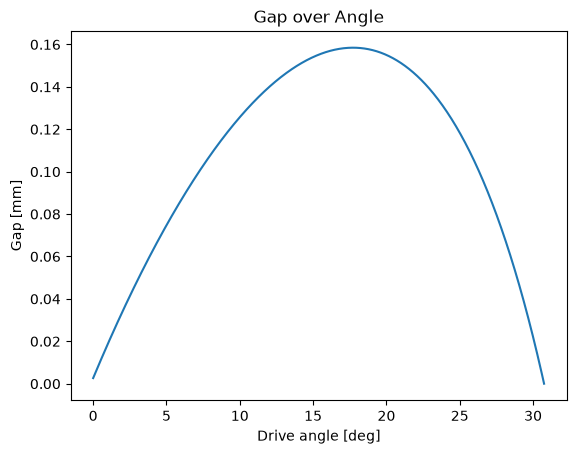

In [3]:
c.plot_gap_over_angle()

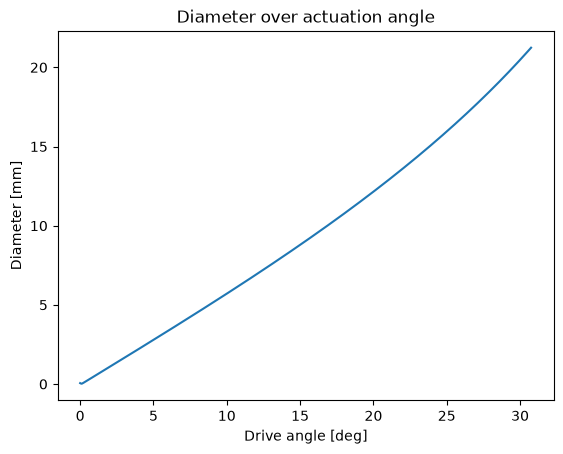

In [4]:
c.plot_diameter_by_angle()

[np.float64(-30.265201666960525), np.float64(-28.143609286708198), np.float64(-21.620050283107748), np.float64(-1.3547283119522378), np.float64(20.424947451341517), np.float64(27.792901759191768), np.float64(30.13489367231573), np.float64(31.086819735968), np.float64(31.55435059487912), np.float64(31.81580129312503), np.float64(31.97606866436451), np.float64(32.0812011248395), np.float64(32.153845056121625), np.float64(32.206148514551685), np.float64(32.24508836247577), np.float64(32.274897847360194), np.float64(32.29826406562382), np.float64(32.31695820186763), np.float64(32.33218562668689), np.float64(32.344789452947154), np.float64(32.35537360223432), np.float64(32.364379766851975), np.float64(32.372136982848744), np.float64(32.37889440377685), np.float64(32.38484347515685), np.float64(32.390133251050045), np.float64(32.39488117229734), np.float64(32.39918077977761), np.float64(32.40310731925978), np.float64(32.40672187136791), np.float64(32.410074433899915), np.float64(32.413206249

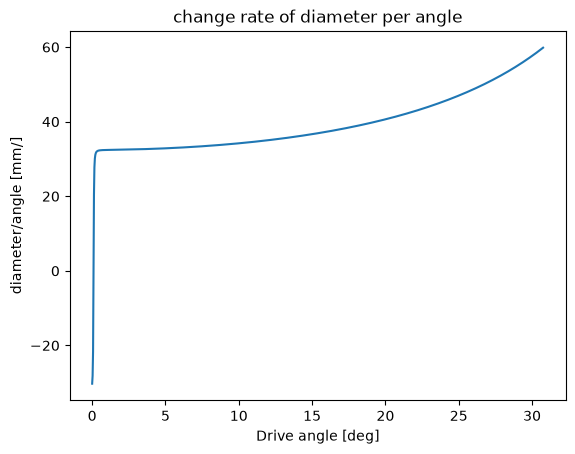

In [5]:
c.plot_rate_of_aperture()

## Motor torque Requirements

In [6]:
stent_lenght = 200 #mm
newton_stent_cm = 4 # N.cm

F_tot = stent_lenght*0.1*newton_stent_cm

F_per_head = F_tot/N

print(f"total Force for stent: {F_tot}N")
print(f"Force per crimp head: {round(F_per_head,3)} N")


print(f"Max Torque at the ring: {round(c.ring_torque(F_per_head)["torque_Nm"],3)} Nm")               # 10 N per tip -> 8.07 N*m at 32.15 deg

c.motor_torque(10.0,1,0.6,1)          # 0.448 N*m at the motor

total Force for stent: 80.0N
Force per crimp head: 5.333 N
Max Torque at the ring: 3.989 Nm


np.float64(7.479800106344906)

## Calculating Pin Forces

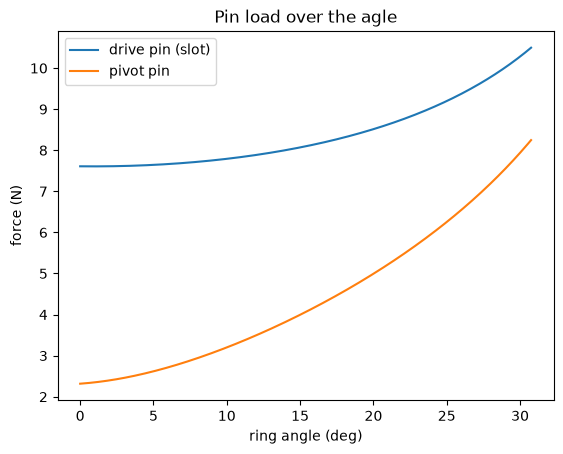

In [12]:
r = c.max_pin_forces(F_per_head)      


plt.plot(r["angles"], r["slot_N"], label="drive pin (slot)")
plt.plot(r["angles"], r["pivot_N"], label="pivot pin")
plt.title("Pin load over the agle")
plt.xlabel("ring angle (deg)"); plt.ylabel("force (N)"); plt.legend(); plt.show()